# WorldForest layers for an EFI plot

This report shows WorldForest / LCFM map layers around a single **EFI 100 m × 100 m plot**
and summarises them as figures and tables. Every statistic is computed for several
**spatial extents** (the plot itself and a surrounding window) so the plot can be compared
with its neighbourhood.

| Section | Figures | Tables / CSV |
|---|---|---|
| Dominant genus | genus map | class distribution (%) |
| Structure | canopy height & FHD maps | mean / std / min / max per extent |
| Landcover | LCFM landcover map (PNG) | class distribution (%) |
| Disturbance atlas | latest disturbance year & agent maps | yearly disturbed area per agent |


In [1]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
from IPython.display import display

from utils import worldforest

# Shared location for all CSVs, figures and the exported report
OUTPUT_DIR = Path("reports")
OUTPUT_DIR.mkdir(exist_ok=True)

## Selection of spatial extent

A file containing EFI sites is used to define spatial extents. 
Only the parameters below need to be changed to run the notebook for another plot:

- `plot_name` – name of the EFI plot (column `plot_name` in the EFI GeoPackage);
- `margin_km` – half-width of the window around the plot used for maps and comparison statistics;
- `extents` – dictionary *label → bounds*; every table below has one column/row per entry, so additional
  windows can be added here.

### Selection of plot

*Output*: the plot name, the CRS of the EFI plot file and the plot bounds (in projected and
geographic coordinates), confirming which plot and window are used in the rest of the notebook.

In [2]:
# EFI file with 100 x 100 m plot polygons in the European equal-area CRS
filename = "/data/open/worldforest/EFI/efi_plot_boxes_gbif_TC2020.gpkg"

df = gpd.read_file(filename)
df = df[df.plot_name.apply(lambda x: "Busa" not in x)]

ERROR 1: PROJ: proj_create_from_database: Open of /opt/conda/envs/python3/share/proj failed


### Pick a plot by clicking its marker on the map or from the drop-down (then run the next cell)

In [3]:
plot_dropdown = worldforest.pick_plot_on_map(df, default="Boussan")

In [4]:
plot_name = plot_dropdown.value
plot_spatial, extents = worldforest.select_plot(df, plot_name, margin_km = 1.0)
worldforest.show_bbox_table(plot_spatial.xy, plot_spatial.latlon, plot_name)

,3035,4326
West,3.580630e+06,0.885486
South,2.281041e+06,43.232314
East,3.580730e+06,0.886847
North,2.281141e+06,43.233318


## Description of the plot and the surroundings

Figures and statistics for the plot and its spatial window, one layer at a time. On every map the
**black rectangle** marks the EFI 100 m × 100 m plot, while the map covers the full window.

### Dominant genus

Map of the dominant tree genus from WorldForest genus layer.

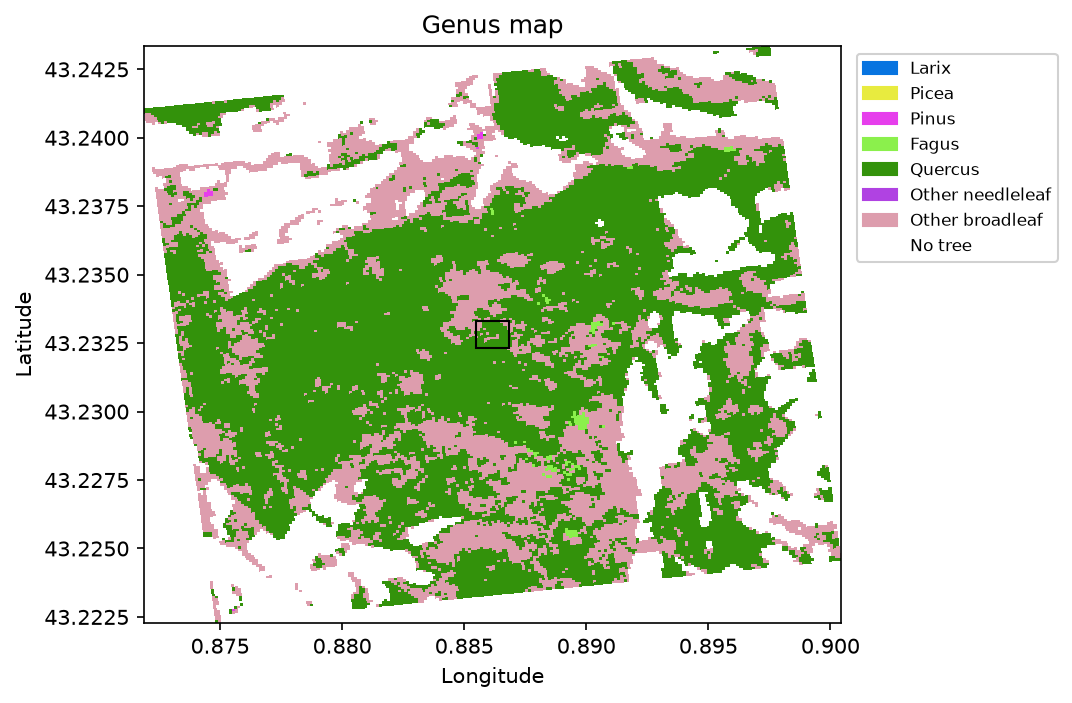

In [5]:
genus_data = worldforest.genus_map_class.load_data(plot_spatial.expanded_xy)
fig = worldforest.genus_map_class.plot(genus_data, overlay_extent=plot_spatial.latlon)

#### Genus distribution

*Output*: table with the share (%) of each genus class per spatial extent. Cells are shaded from
light (0 %) to dark green (100 %). Classes absent in all extents are not shown. The notebook stops
with an error if the plot itself contains no valid genus pixels.

In [6]:
genus_stats_df = worldforest.class_distribution_table(worldforest.genus_map_class, extents)

plot_extent = next(iter(extents))
if (genus_stats_df[plot_extent] == 0).all():
    raise ValueError(f"No valid genus pixels found inside the {plot_extent} bounds.")

# print("Genus class distribution (%)")
display(worldforest.style_table(genus_stats_df, vmin=0, vmax=100))

class,class_name,100m plot,2 km window
2,Pinus,0.0,0.0
3,Fagus,0.0,0.3
4,Quercus,82.0,47.6
6,Other broadleaf,18.0,23.9
7,No tree,0.0,28.3


Figure showing  the share (%) of each genus class per spatial extent.

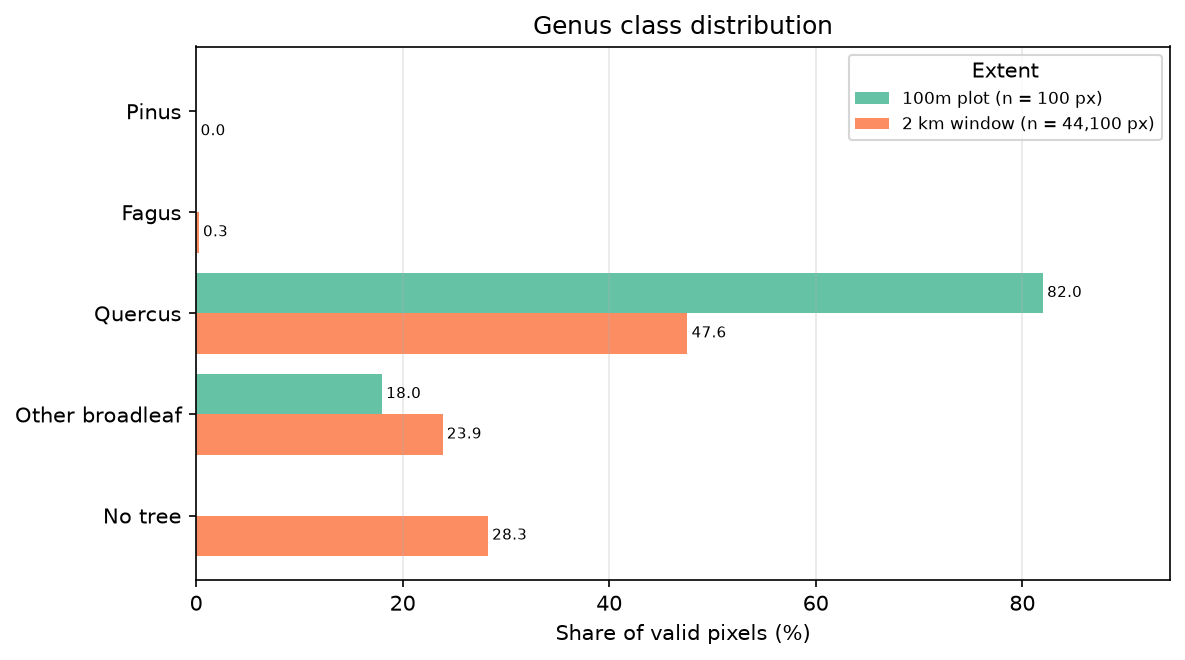

In [7]:
fig = worldforest.plot_class_distribution(genus_stats_df, title="Genus class distribution")

#### Save distribution

*Output*: `reports/<plot_name>_genus_distribution.csv` containing the table above.

In [8]:
# save the data as csv file
genus_csv = OUTPUT_DIR / f"{plot_name}_genus_distribution.csv"
genus_stats_df.to_csv(genus_csv, index=False)
print(f"Saved: {genus_csv}")

Saved: reports/Boussan_genus_distribution.csv


### Structure information (height, cover, FHD)

#### Table
*Output*: table with mean of canopy height (m) and foliage height diversity (FHD) for each spatial extent.

In [9]:
structure_layers = {
    "canopy_height": worldforest.canopy_height_class,
    "fhd": worldforest.foliage_height_diversity_class,
}
structure_stats_df = worldforest.layer_stats_table(structure_layers, extents)
display(worldforest.style_table(structure_stats_df))


layer_name,extent_name,mean
canopy_height,100m plot,17.5
canopy_height,2 km window,12.1
fhd,100m plot,2.2
fhd,2 km window,1.8


#### Canopy height and FHD plots for given extent.

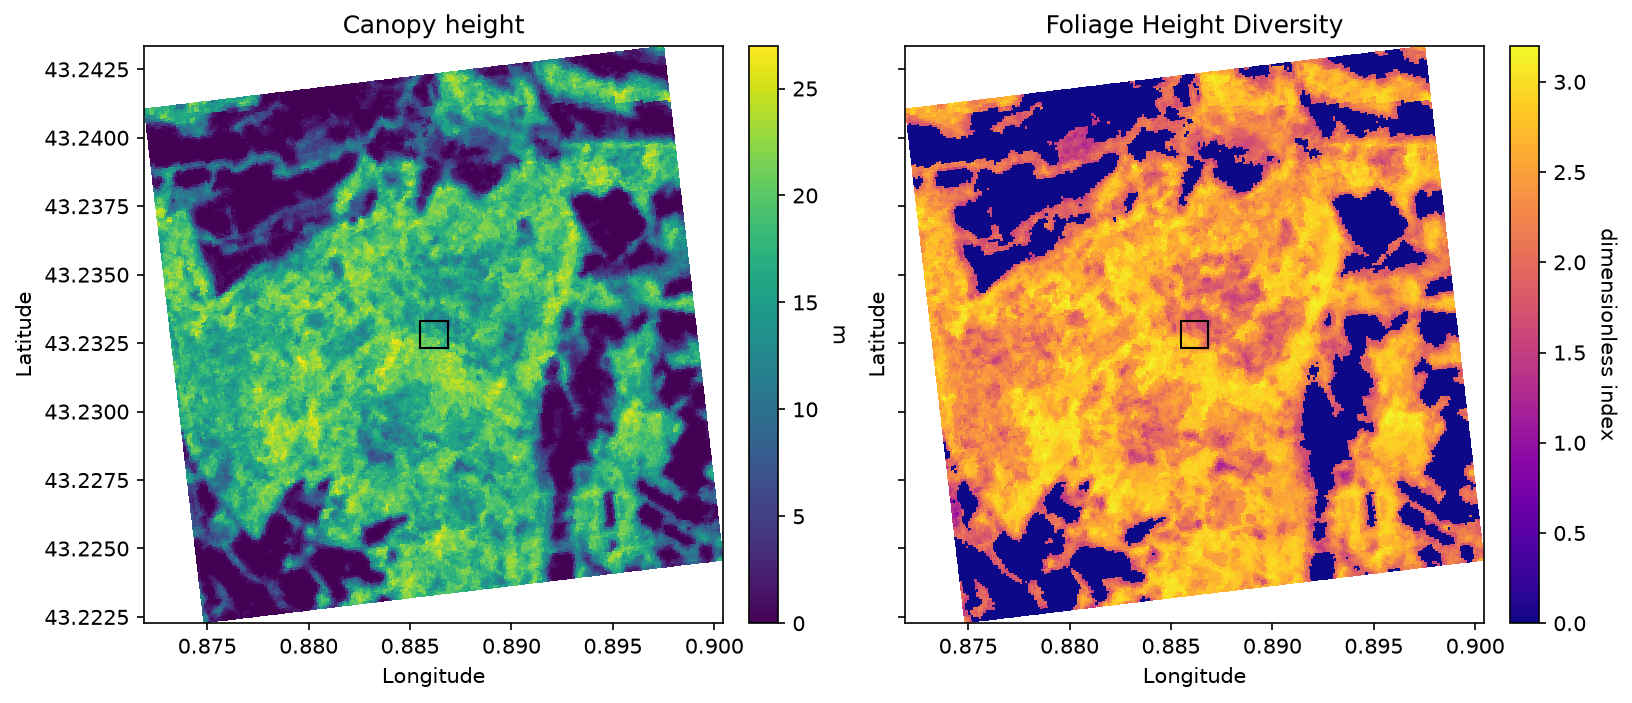

In [10]:
data_ch = worldforest.canopy_height_class.load_data(plot_spatial.expanded_xy)
data_fhd = worldforest.foliage_height_diversity_class.load_data(plot_spatial.expanded_xy)

fig, ax = plt.subplots(1,2, figsize=(12, 5), dpi=150, sharey= True)
fig = worldforest.canopy_height_class.plot(data_ch, ax=ax[0], overlay_extent=plot_spatial.latlon)
fig = worldforest.foliage_height_diversity_class.plot(data_fhd, ax=ax[1], overlay_extent=plot_spatial.latlon)

#### Plots showing distribution of canopy height and FHD for given extent. Dotted lines show mean values.
- The distribution represents the probability density of occurance of a height.

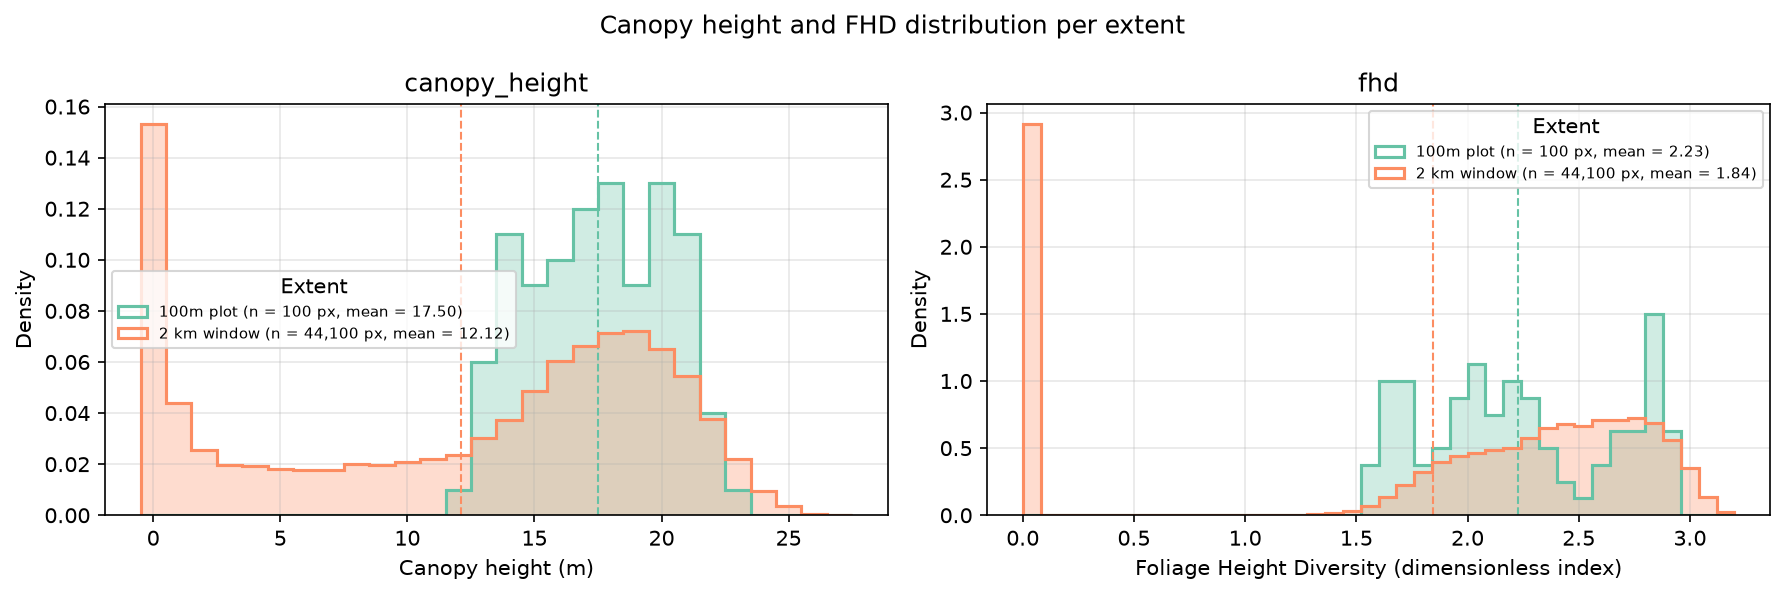

In [11]:
fig = worldforest.plot_value_distributions(
    structure_layers, extents, title="Canopy height and FHD distribution per extent"
)
plt.show()

### Landcover map from LCFM 10m.
- Earth's surface is mapped to 11 discrete thematic classes
- help track global environmental shifts like deforestation and urbanization

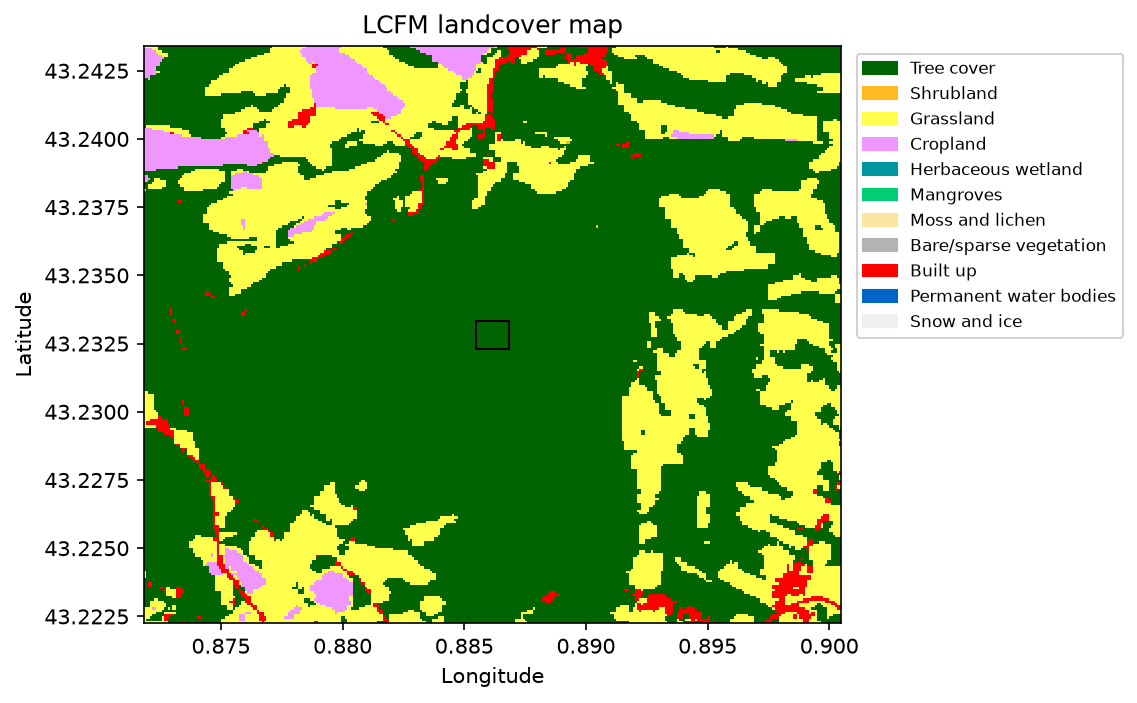

In [13]:
# LCFM landcover (collection "lcfm-lcm-10"), loaded via STAC for the plot + margin window
landcover_data = worldforest.land_cover.load_data(plot_spatial.expanded_xy)
fig = worldforest.land_cover.plot(landcover_data, overlay_extent=plot_spatial.latlon)

*Output*: LCFM 10 m landcover map (collection `lcfm-lcm-10`, loaded from the Terrascope STAC
catalogue) for the window around the plot, saved as `reports/<plot_name>_landcover_map.png`.

In [14]:
landcover_map_png = OUTPUT_DIR / f"{plot_name}_landcover_map.png"
fig.savefig(landcover_map_png, dpi=300, bbox_inches="tight")
print(f"Saved: {landcover_map_png}")

Saved: reports/Boussan_landcover_map.png


#### Landcover class distribution
- Shows the distribution of the classes in the given extent. 

In [15]:
# *Output*: table with the share (%) of each landcover class per spatial extent (shaded 0–100 %),
# saved as `reports/<plot_name>_landcover_distribution.csv`. For a forest plot the *Tree cover*
# class is expected to dominate the plot column; the window column shows the surrounding mosaic.

landcover_stats_df = worldforest.class_distribution_table(worldforest.land_cover, extents)
landcover_csv = OUTPUT_DIR / f"{plot_name}_landcover_distribution.csv"
landcover_stats_df.to_csv(landcover_csv, index=False)
print(f"Saved: {landcover_csv}")

print("Landcover class distribution (%)")
display(worldforest.style_table(landcover_stats_df, vmin=0, vmax=100))

Saved: reports/Boussan_landcover_distribution.csv
Landcover class distribution (%)


class,class_name,100m plot,2 km window
10,Tree cover,100.0,68.5
20,Shrubland,0.0,0.0
30,Grassland,0.0,26.2
40,Cropland,0.0,3.3
90,Built up,0.0,1.9


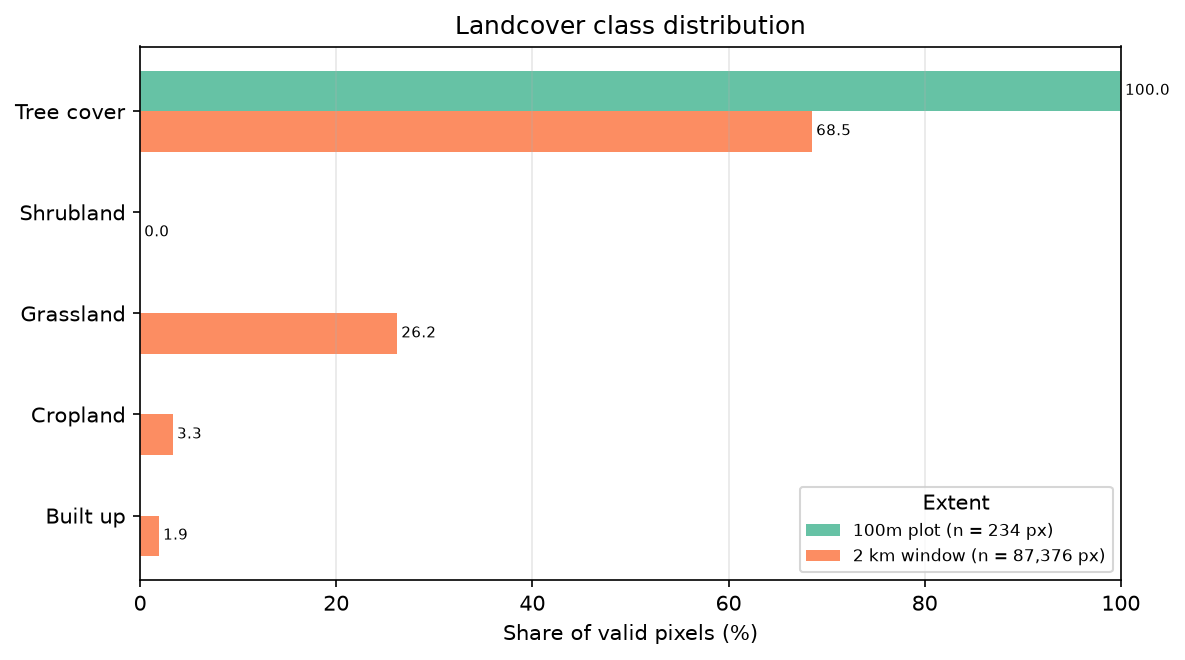

In [16]:
fig = worldforest.plot_class_distribution(landcover_stats_df, title="Landcover class distribution")

### Disturbance atlas

Annual disturbance maps (1985–2024) combined with the disturbance-agent layer.

*Output*: a summary table listing, for every spatial extent and every **year with at least one
disturbed pixel**, the total number of valid pixels, the disturbed share (%) and the number of
disturbed pixels per agent. Darker cells indicate higher values within each column.

In [17]:
years = list(worldforest.years)
disturbance_df = worldforest.compute_disturbance_stats(years, extents)

print("=== Disturbance Summary Statistics (Years with Disturbances Only) ===")
print(f"Study period: {years[0]} - {years[-1]}")
print(f"Plot: {plot_name}; extents: {', '.join(extents)}")
print(f"Years with disturbances: {disturbance_df['Year'].nunique()} out of {len(years)}\n")

display(worldforest.style_table(disturbance_df, columns=[c for c in disturbance_df.columns if c not in ("Extent", "Year", "Total_Pixels")]))

=== Disturbance Summary Statistics (Years with Disturbances Only) ===
Study period: 1985 - 2024
Plot: Boussan; extents: 100m plot, 2 km window
Years with disturbances: 17 out of 40



Extent,Year,Total_Pixels,Disturbed_Pixels,Disturbed_%,Harvest (pixels)
2 km window,1985,4900,23,0.5,23
2 km window,1987,4900,11,0.2,11
2 km window,1988,4900,11,0.2,11
2 km window,1991,4900,13,0.3,13
2 km window,1992,4900,15,0.3,15
2 km window,1994,4900,52,1.1,52
2 km window,1997,4900,4,0.1,4
2 km window,1999,4900,15,0.3,15
2 km window,2001,4900,12,0.2,12
2 km window,2003,4900,82,1.7,82


##### Plot showing the cause of disturbance every year for plot within 2km window.
- The color represents the type of disturbance. 

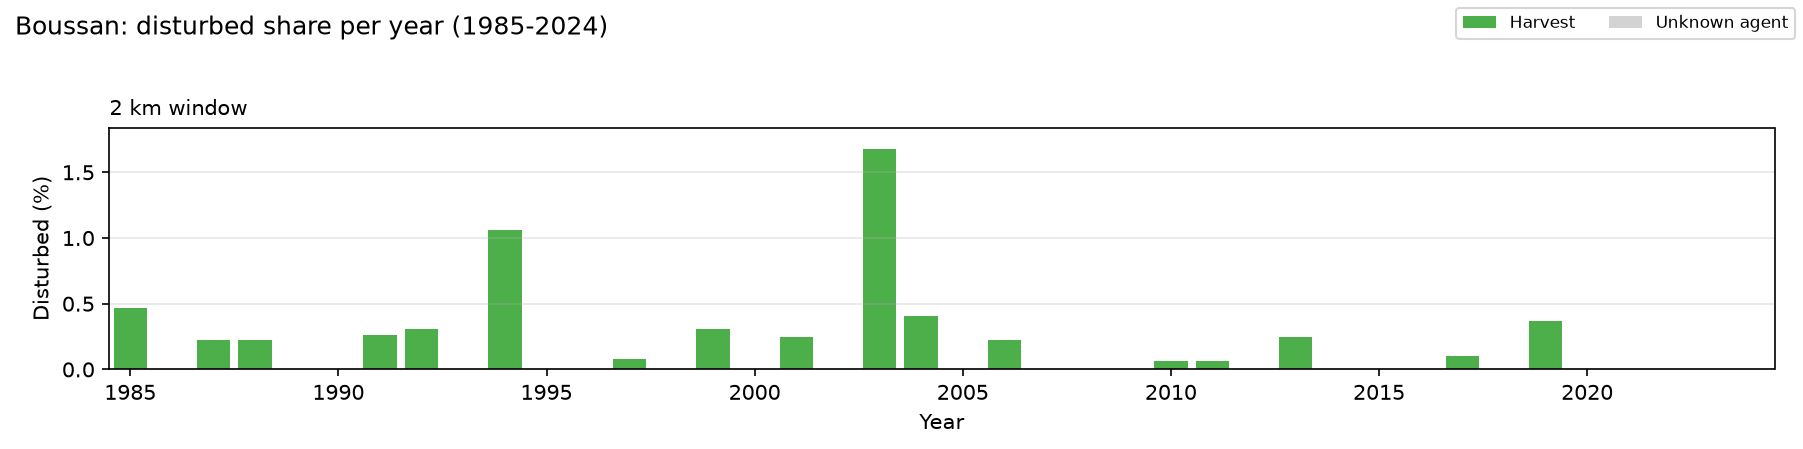

In [18]:
fig = worldforest.plot_disturbance_timeline(
    disturbance_df,
    title=f"{plot_name}: disturbed share per year ({years[0]}-{years[-1]})",
)

#### Latest disturbance year
For every disturbed pixel, the **year of the most recent disturbance**
(colour scale 1985–2024). Undisturbed pixels are blank.

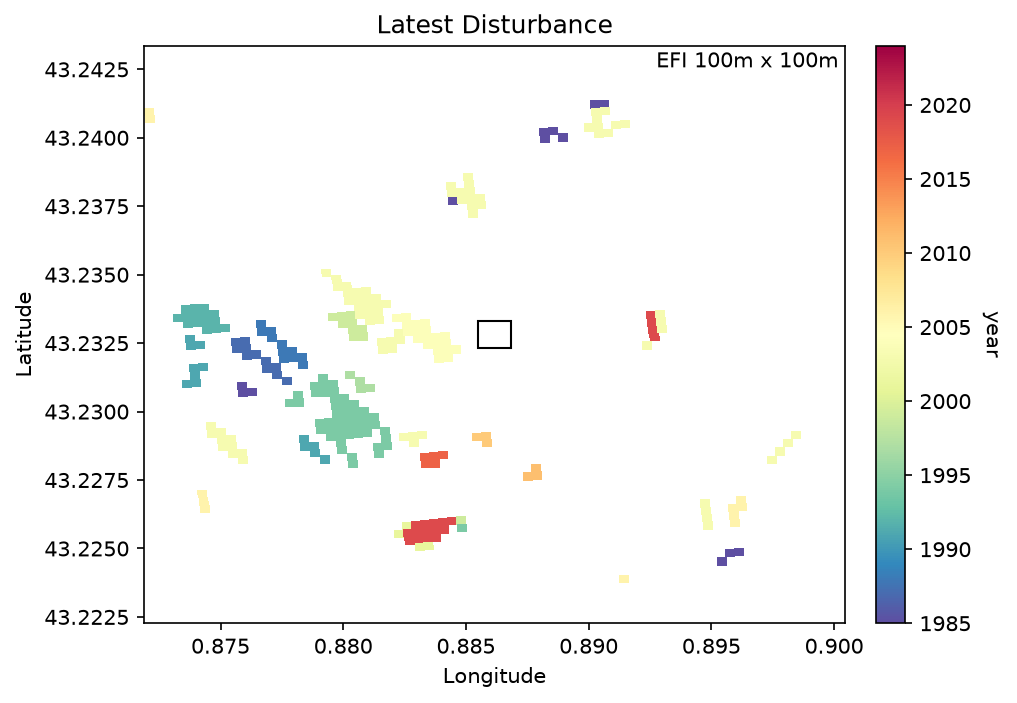

In [19]:
data = worldforest.latest_disturbance_class.load_data(plot_spatial.expanded_xy)
kargs = {"vmin":1985, "vmax":2024}
fig = worldforest.latest_disturbance_class.plot(
    data, 
    overlay_extent=plot_spatial.latlon,
    overlay_label="EFI 100m x 100m",
    **kargs)

#### Dominant disturbance agent

The map of the aggregated disturbance agent (e.g. harvest, wind/bark beetle, fire) per
pixel, using the agent legend on the right.

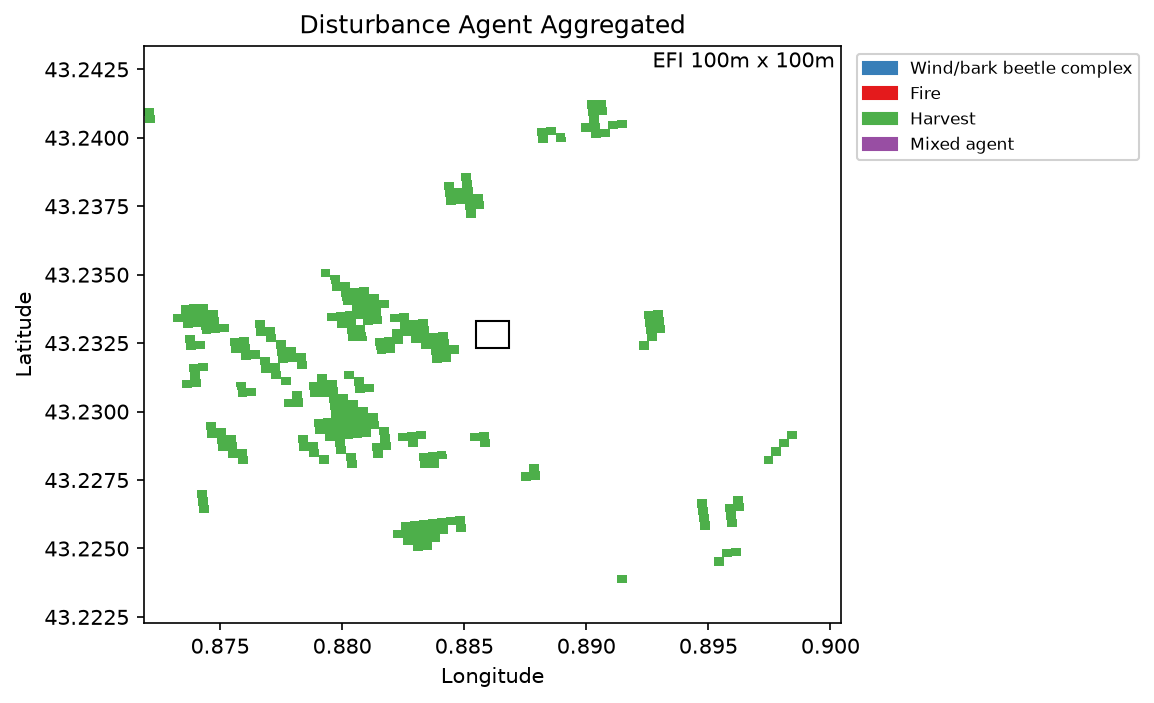

In [20]:
data = worldforest.agent_aggregated_class.load_data(plot_spatial.expanded_xy)
fig = worldforest.agent_aggregated_class.plot(data, overlay_extent=plot_spatial.latlon, overlay_label="EFI 100m x 100m")